# RiMEA 15: Movement of a Large Crowd of Pedestrians Around a Corner

The goal is to assess the extent to which the movement of persons around a corner affects the calculated evacuation time. 3 scenarios are constructed: Scenario 1 has a 20 m x 81.4 m straight corridor geometry, whereas Scenario 2 has a curve and Scenario 3 has a shorter corridor of the dimensions 20 m x 50 m (RiMEA Guideline 4.1.1 Fig. 19). Time taken for all persons to reach the destination is compared to determine how much a corner influences a simulation result. Ideally, the result from the "corner" would be in between the two results for Scenario 1 and Scenario 3.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:37 CEST


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon
from shapely.plotting import plot_polygon
import jupedsim as jps
from jupedsim_scenarios import load_scenario, run_scenario, run_sweep

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

##  Load and Run Scenario 1

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-15-large-crowd-corner-1.zip"
scenario1 = load_scenario(str(SCENARIO_ZIP))
print(scenario1.summary())
result1 = run_scenario(scenario1, seed=42)
walkable1 = scenario1.walkable_polygon
df1 = result1.trajectory_dataframe()

Scenario: scenario_files/Rimea-15-large-crowd-corner-1.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~500
    jps-distributions_0: 500 agents


## Load and Run Scenario 2

In [6]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-15-large-crowd-corner-2.zip"
scenario2 = load_scenario(str(SCENARIO_ZIP))
print(scenario2.summary())
result2 = run_scenario(scenario2, seed=42)
walkable2 = scenario2.walkable_polygon
df2 = result2.trajectory_dataframe()

Scenario: scenario_files/Rimea-15-large-crowd-corner-2.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~500
    jps-distributions_0: 500 agents


## Load and Run Scenario 3

In [7]:
SCENARIO_ZIP = Path("scenario_files") / "Rimea-15-large-crowd-corner-3.zip"
scenario3 = load_scenario(str(SCENARIO_ZIP))
print(scenario3.summary())
result3 = run_scenario(scenario3, seed=42)
walkable3 = scenario3.walkable_polygon
df3 = result3.trajectory_dataframe()

Scenario: scenario_files/Rimea-15-large-crowd-corner-3.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~500
    jps-distributions_0: 500 agents


## Scenario figure

Geometry of the three corridor variants from the loaded scenarios.

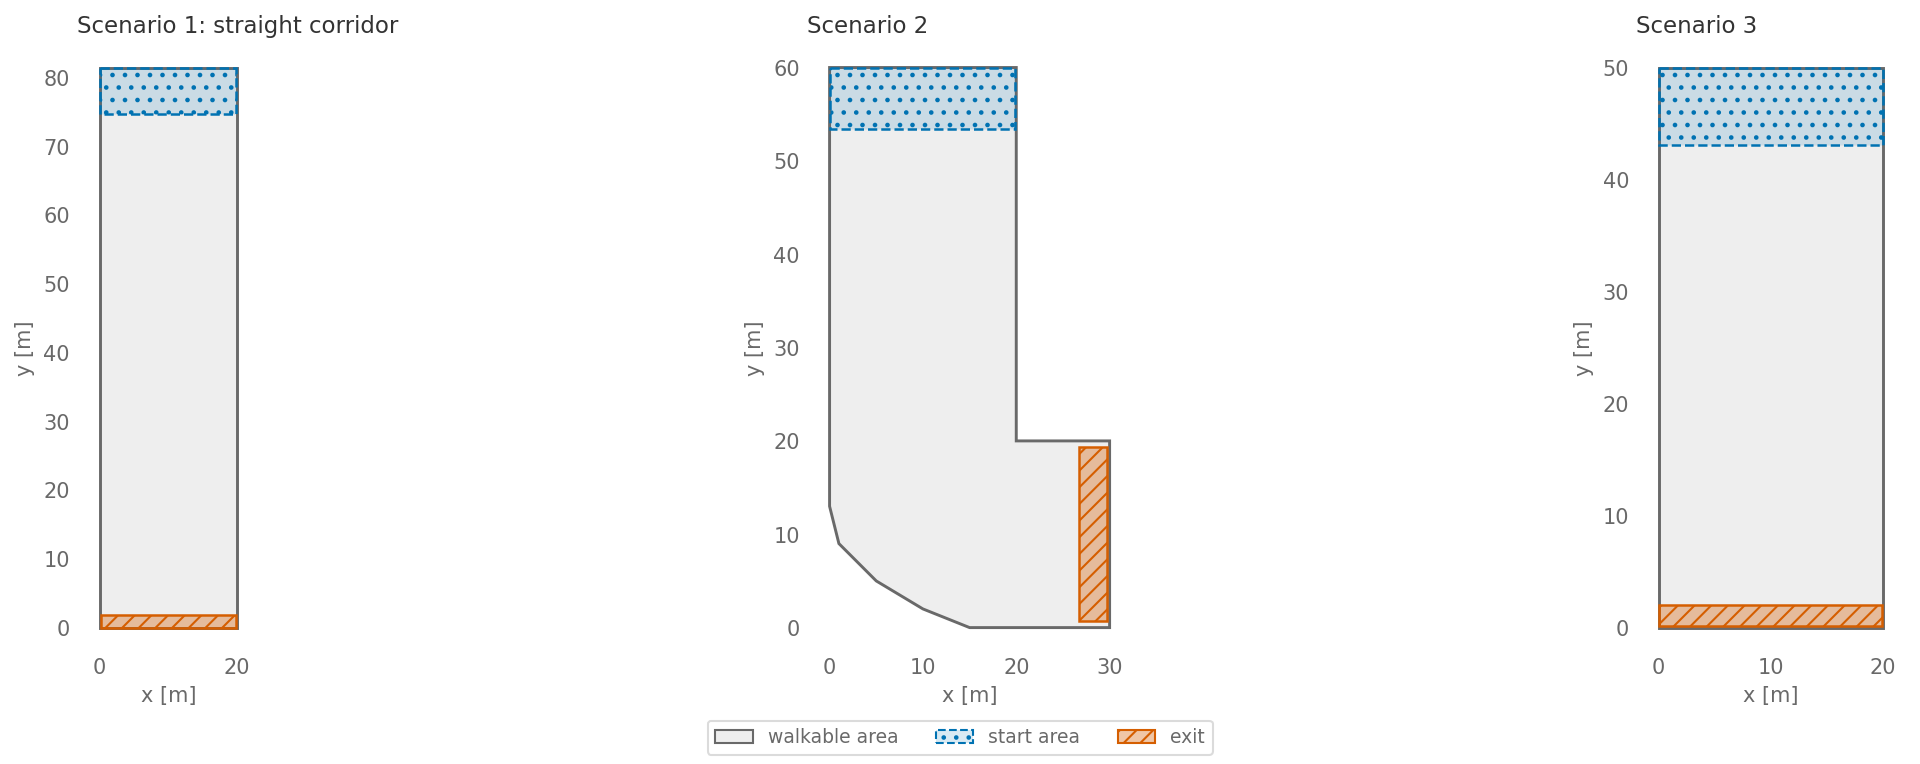

In [8]:
# Scenario geometry of each variant from the loaded ZIPs.
with plt.rc_context(VV_RC):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")
    for ax, (scen, label) in zip(axes, [(scenario1, "Scenario 1: straight corridor"), (scenario2, "Scenario 2"), (scenario3, "Scenario 3")]):
        handles = vv_draw_scenario(ax, scen)
        ax.set_title(label, loc="left")
    fig.legend(handles=handles, loc="outside lower center", ncol=3)
    plt.show()

## Exit Times of All Scenarios

In [9]:
def get_exit_times(df, result):
    et = (
        df.sort_values(["id", "frame"])
        .groupby("id")
        .tail(1)[["id", "frame"]]
        .rename(columns={"frame": "exit_frame"})
    )
    et["exit_time"] = et["exit_frame"] / result.frame_rate
    return et

exit_times1 = get_exit_times(df1, result1)
exit_times2 = get_exit_times(df2, result2)
exit_times3 = get_exit_times(df3, result3)

print("Max exit time (df1):", exit_times1["exit_time"].max())
print("Max exit time (df2):", exit_times2["exit_time"].max())
print("Max exit time (df3):", exit_times3["exit_time"].max())

Max exit time (df1): 106.5
Max exit time (df2): 185.5
Max exit time (df3): 78.8


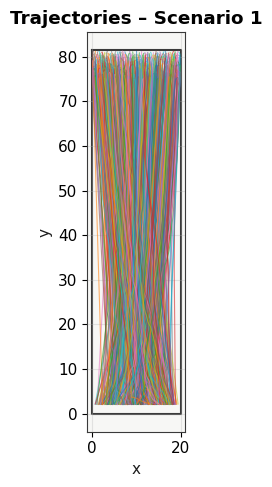

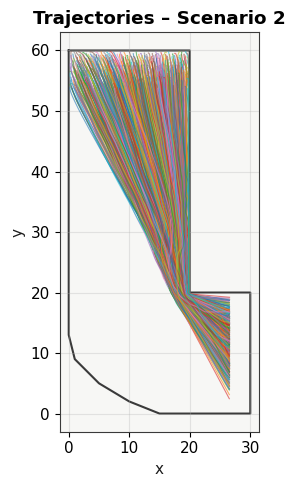

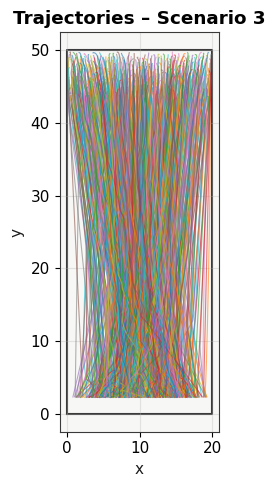

In [10]:
scenarios = [
    (df1, walkable1, "Scenario 1"),
    (df2, walkable2, "Scenario 2"),
    (df3, walkable3, "Scenario 3"),
]

for df, walkable, title in scenarios:
    fig, ax = plt.subplots()

    # plot walkable area (assumes a GeoDataFrame/shapely geometry with .boundary or .exterior)
    # adjust this depending on how your walkable is stored
    if hasattr(walkable, "plot"):
        walkable.plot(ax=ax, facecolor="none", edgecolor="#3a3a3a", linewidth=1.5, zorder=1)
    else:
        ax.plot(*walkable.exterior.xy, color="#3a3a3a", linewidth=1.5, zorder=1)

    # plot each agent's trajectory
    for agent_id, traj in df.groupby("id"):
        traj_sorted = traj.sort_values("frame")
        ax.plot(traj_sorted["x"], traj_sorted["y"], alpha=0.6, linewidth=0.8, zorder=2)

    ax.set_title(f"Trajectories – {title}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

    plt.tight_layout()
    plt.show()

## Result figure

Evacuation time of the three scenarios. Acceptance: Scenario 2 lies between Scenario 3 and Scenario 1 (documented failure).

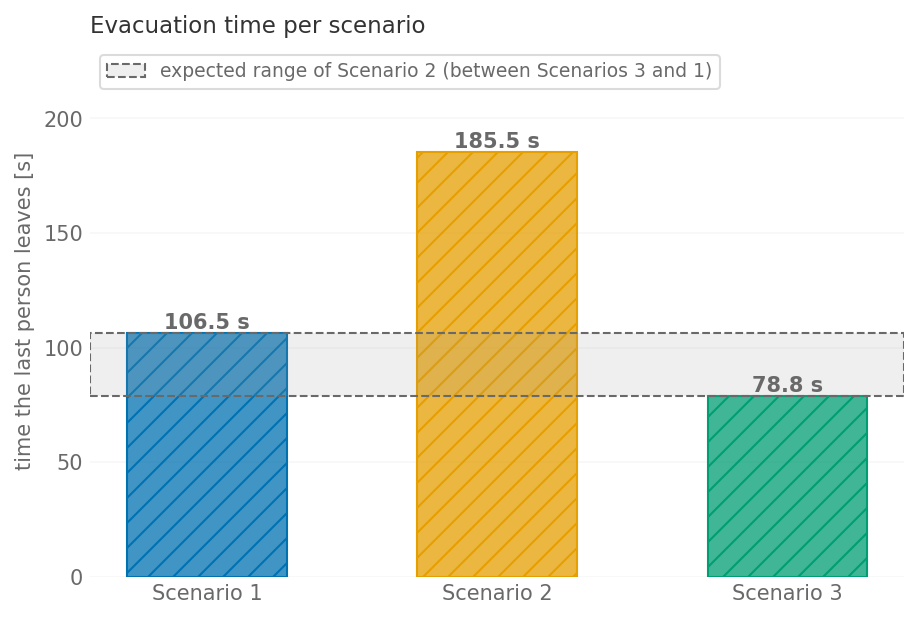

In [11]:
# Time the last person leaves in each scenario; Scenario 2 must lie between Scenario 3 and Scenario 1.
t_max = [exit_times1["exit_time"].max(), exit_times2["exit_time"].max(), exit_times3["exit_time"].max()]
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(7, 4.6))
    bars = ax.bar(["Scenario 1", "Scenario 2", "Scenario 3"], t_max,
                  color=[to_rgba(c, 0.75) for c in (VV_BLUE, VV_ORANGE, VV_GREEN)],
                  edgecolor=[VV_BLUE, VV_ORANGE, VV_GREEN], hatch="//", width=0.55)
    ax.bar_label(bars, fmt="%.1f s", color="dimgrey", fontweight="semibold")
    ax.axhspan(min(t_max[0], t_max[2]), max(t_max[0], t_max[2]), facecolor=to_rgba("#999999", 0.15),
               edgecolor="dimgrey", linestyle="--", linewidth=1.0,
               label="expected range of Scenario 2 (between Scenarios 3 and 1)")
    ax.set_ylabel("time the last person leaves [s]")
    ax.set_ylim(0, max(t_max) * 1.25)
    ax.set_title("Evacuation time per scenario", loc="left")
    ax.legend(loc="upper left")
    ax.grid(axis="x", visible=False)
    plt.show()

## Acceptance - FAIL
RiMEA Test 15 expects Scenario 2 to have a evacuation time in between of Scenario 1 and 3. This is clearly not the case, corners have more effect on the behavior than they should have.

This assertion FAILS. It is documented as a model limitation of the collision-free speed model around a corner. Measured (seed 42): max exit time Scenario 2 230.7 s, Scenario 1 124.8 s, Scenario 3 102.8 s.


In [12]:
try:
    assert exit_times2["exit_time"].max() >= exit_times3["exit_time"].max() and exit_times2["exit_time"].max() <= exit_times1["exit_time"].max()
except AssertionError:
    print(f"FAIL (documented model limitation): Scenario 2 max exit time {exit_times2['exit_time'].max():.1f} s is not between Scenario 1 ({exit_times1['exit_time'].max():.1f} s) and Scenario 3 ({exit_times3['exit_time'].max():.1f} s).")
else:
    raise AssertionError("XPASS: expected failure did not occur; review the model limitation note.")
result1.cleanup()
result2.cleanup()
result3.cleanup()


FAIL (documented model limitation): Scenario 2 max exit time 185.5 s is not between Scenario 1 (106.5 s) and Scenario 3 (78.8 s).


1